# Hệ thống gợi ý phim bằng KNN – MovieLens
Chạy lần lượt từng ô (Run All). Logic nằm trong `recsys.py`.

In [18]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import recsys

DATASET = "100k"   # đổi thành "1m" để mở rộng
ratings, movies = recsys.load_movielens(DATASET)
n_users, n_items = ratings.user.max() + 1, len(movies)
print(f"{len(ratings):,} ratings | {n_users} users | {n_items} phim")
print(f"Độ thưa: {1 - len(ratings)/(n_users*n_items):.2%}")
ratings.head()
ratings.head()

100,000 ratings | 943 users | 1682 phim
Độ thưa: -654.03%


C:\Users\VuLeThanh\AppData\Local\Temp\ipykernel_23036\717961156.py:9: RuntimeWarning: overflow encountered in scalar multiply
  print(f"Độ thưa: {1 - len(ratings)/(n_users*n_items):.2%}")


,user_id,movie_id,rating,ts,item,user
0,196,242,3,881250949,241,195
1,186,302,3,891717742,301,185
2,22,377,1,878887116,376,21
3,244,51,2,880606923,50,243
4,166,346,1,886397596,345,165


## 1. Khám phá dữ liệu

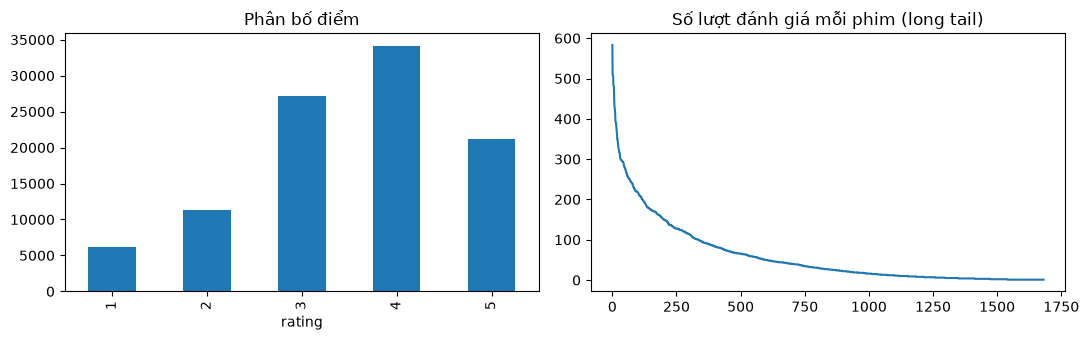

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="Phân bố điểm")
ratings.groupby("item").size().sort_values(ascending=False).reset_index(drop=True).plot(
    ax=ax[1], title="Số lượt đánh giá mỗi phim (long tail)")
plt.tight_layout(); plt.show()

## 2. Chia train/test (80/20)

In [12]:
train, test = recsys.split(ratings)
R_train = recsys.to_matrix(train, n_users, n_items)
print(len(train), len(test))

80000 20000


## 3. Baseline

In [13]:
item_mean = np.where((R_train>0).sum(0)>0, R_train.sum(0)/np.maximum((R_train>0).sum(0),1), R_train.sum()/(R_train>0).sum())
P_base = np.tile(item_mean, (n_users, 1))
P_pop = np.tile((R_train>0).sum(0).astype(float), (n_users, 1))   # xếp theo độ phổ biến
mae, rmse = recsys.rating_metrics(P_base, test)
p, r = recsys.ranking_metrics(P_pop, R_train, test, k=10)
print(f"Item-mean  MAE={mae:.4f} RMSE={rmse:.4f}")
print(f"Popularity P@10={p:.4f} R@10={r:.4f}")

Item-mean  MAE=0.8123 RMSE=1.0210
Popularity P@10=0.1354 R@10=0.1371


## 4. Thử nghiệm KNN: Item-based vs User-based, K = 5, 10, 20, 50

In [14]:
rows = []
for mode in ["item", "user"]:
    for k in [5, 10, 20, 50]:
        t0 = time.time(); m = recsys.KNNRecommender(k, mode, shrink=10).fit(R_train); fit_t = time.time() - t0
        mae, rmse = recsys.rating_metrics(m.P, test)
        p, r = recsys.ranking_metrics(m.P, R_train, test, k=10)
        rows.append(dict(mode=mode, K=k, MAE=mae, RMSE=rmse, **{"P@10": p, "R@10": r}, fit_sec=fit_t))
res = pd.DataFrame(rows)
res.round(4)

,mode,K,MAE,RMSE,P@10,R@10,fit_sec
0,item,5,0.8024,1.0470,0.0159,0.0177,0.2513
1,item,10,0.7742,1.0084,0.0098,0.0106,0.1474
2,item,20,0.7456,0.9678,0.0067,0.0075,0.1122
3,item,50,0.7248,0.9335,0.0051,0.0066,0.3057
4,user,5,0.8242,1.0672,0.0475,0.0539,0.0599
5,user,10,0.7944,1.0296,0.0263,0.0258,0.0572
6,user,20,0.7689,0.9961,0.0175,0.0136,0.0540
7,user,50,0.7430,0.9589,0.0114,0.0087,0.3087


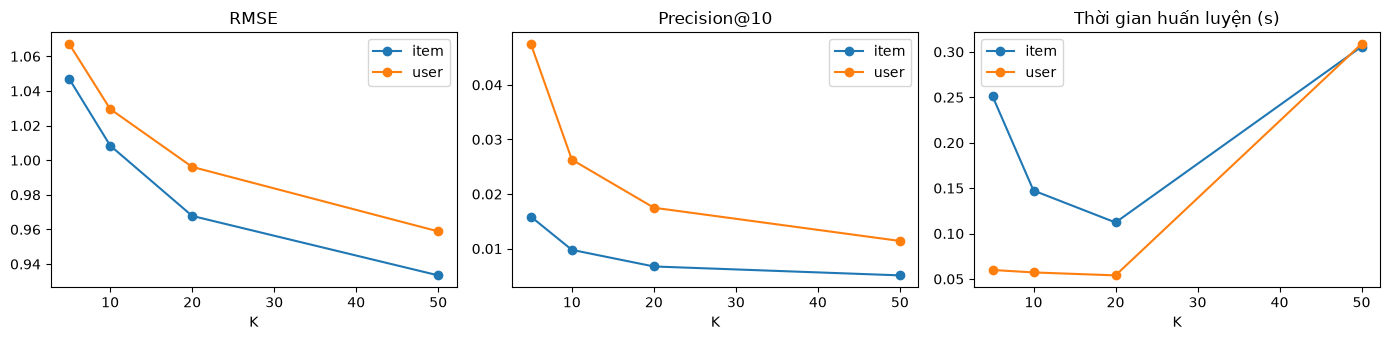

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for mode, g in res.groupby("mode"):
    ax[0].plot(g.K, g.RMSE, marker="o", label=mode)
    ax[1].plot(g.K, g["P@10"], marker="o", label=mode)
    ax[2].plot(g.K, g.fit_sec, marker="o", label=mode)
for a, t in zip(ax, ["RMSE", "Precision@10", "Thời gian huấn luyện (s)"]):
    a.set_title(t); a.set_xlabel("K"); a.legend()
plt.tight_layout(); plt.show()

## 5. Ảnh hưởng của shrinkage (K=20, item-based)

In [16]:
rows = []
for s in [0, 10, 25, 50]:
    m = recsys.KNNRecommender(20, "item", shrink=s).fit(R_train)
    mae, rmse = recsys.rating_metrics(m.P, test)
    p, r = recsys.ranking_metrics(m.P, R_train, test, k=10)
    rows.append(dict(shrink=s, MAE=mae, RMSE=rmse, **{"P@10": p, "R@10": r}))
pd.DataFrame(rows).round(4)

,shrink,MAE,RMSE,P@10,R@10
0,0,0.7791,1.0098,0.0107,0.0112
1,10,0.7456,0.9678,0.0067,0.0075
2,25,0.7432,0.9628,0.0070,0.0074
3,50,0.7410,0.9589,0.0067,0.0089


## 6. Ví dụ gợi ý

In [17]:
best = recsys.KNNRecommender(20, "item", shrink=10).fit(recsys.to_matrix(ratings, n_users, n_items))
u = 0
idx, pred = best.recommend(u, 10)
print("Gợi ý cho user", u); display(movies.loc[idx, ["title", "genres"]].assign(pred=pred.round(2)))

q = movies.index[movies.title.str.contains("Toy Story", regex=False)][0]
idx, sim = best.similar_items(q, 10)
print("Phim giống:", movies.title[q]); display(movies.loc[idx, ["title", "genres"]].assign(sim=sim.round(3)))

Gợi ý cho user 0


,title,genres,pred
813,"Great Day in Harlem, A (1994)",Documentary,5.0
1514,Wings of Courage (1995),Adventure|Romance,5.0
1535,Aiqing wansui (1994),Drama,5.0
1598,Someone Else's America (1995),Drama,5.0
1466,"Saint of Fort Washington, The (1993)",Drama,5.0
710,"Substance of Fire, The (1996)",Drama,5.0
1499,Santa with Muscles (1996),Comedy,5.0
1397,Anna (1996),Drama,5.0
1524,"Object of My Affection, The (1998)",Comedy|Romance,5.0
1652,Entertaining Angels: The Dorothy Day Story (1996),Drama,5.0


Phim giống: Toy Story (1995)


,title,genres,sim
173,Raiders of the Lost Ark (1981),Action|Adventure,0.262
49,Star Wars (1977),Action|Adventure|Romance|Sci-Fi|War,0.229
587,Beauty and the Beast (1991),Animation|Children's|Musical,0.227
27,Apollo 13 (1995),Action|Drama|Thriller,0.218
94,Aladdin (1992),Animation|Children's|Comedy|Musical,0.205
209,Indiana Jones and the Last Crusade (1989),Action|Adventure,0.199
171,"Empire Strikes Back, The (1980)",Action|Adventure|Drama|Romance|Sci-Fi|War,0.193
180,Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,0.185
63,"Shawshank Redemption, The (1994)",Drama,0.182
21,Braveheart (1995),Action|Drama|War,0.182


## 7. Phân tích & kết luận (điền theo số liệu ở bảng trên)
**Ưu điểm:** dễ hiểu, không cần huấn luyện phức tạp, giải thích được ("giống phim X bạn đã thích"), item-based ổn định vì sở thích phim ít đổi.

**Hạn chế:** dữ liệu thưa (~94% ô trống) làm similarity thiếu tin cậy; cold-start (user/phim mới); tốn bộ nhớ O(n²) cho ma trận tương đồng; thiên lệch phổ biến.

**Ảnh hưởng của K:** K nhỏ → nhiễu, phương sai cao; K lớn → làm mịn quá mức, kéo dự đoán về trung bình, thời gian tăng. Ghi lại K tối ưu từ bảng kết quả.

**Cách cải thiện:** shrinkage (đã dùng), chuẩn hoá theo user/item (đã dùng), kết hợp content-based (thể loại), matrix factorization (SVD/ALS), ANN (FAISS) cho dữ liệu lớn, đánh giá theo thời gian thay vì split ngẫu nhiên.